**Ques1**

In [6]:
import ssl
import re
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

try:
    ssl._create_default_https_context = ssl._create_unverified_context
except AttributeError:
    pass

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

paragraph = (
    "Artificial intelligence is rapidly transforming the modern technological landscape. "
    "Machine learning algorithms can analyze massive datasets in a fraction of a second. "
    "From healthcare diagnostics to autonomous vehicles, AI systems are automating complex operations. "
    "However, ethical considerations and data privacy must remain primary concerns for developers. "
    "Engineers must construct algorithms that are fair, transparent, and robust. "
    "The future of global innovation depends on responsible and sustainable AI deployment."
)

clean_paragraph = re.sub(r'[^\w\s]', '', paragraph.lower())

sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_paragraph)

python_split_words = clean_paragraph.split()
nltk_tokenized_words = word_tokenize(clean_paragraph)

print("Python split():", python_split_words[:8])
print("NLTK word_tokenize():", nltk_tokenized_words[:8])

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]

fdist = FreqDist(filtered_words)
print("\nTop 10 Word Frequencies:")
for word, frequency in fdist.most_common(10):
    print(f"{word}: {frequency}")

Python split(): ['artificial', 'intelligence', 'is', 'rapidly', 'transforming', 'the', 'modern', 'technological']
NLTK word_tokenize(): ['artificial', 'intelligence', 'is', 'rapidly', 'transforming', 'the', 'modern', 'technological']

Top 10 Word Frequencies:
algorithms: 2
ai: 2
must: 2
artificial: 1
intelligence: 1
rapidly: 1
transforming: 1
modern: 1
technological: 1
landscape: 1


**Ques2**

In [7]:
import ssl
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

try:
    ssl._create_default_https_context = ssl._create_unverified_context
except AttributeError:
    pass

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

paragraph = (
    "Artificial intelligence is rapidly transforming the modern technological landscape. "
    "Machine learning algorithms can analyze massive datasets in a fraction of a second. "
    "From healthcare diagnostics to autonomous vehicles, AI systems are automating complex operations. "
    "However, ethical considerations and data privacy must remain primary concerns for developers. "
    "Engineers must construct algorithms that are fair, transparent, and robust. "
    "The future of global innovation depends on responsible and sustainable AI deployment."
)

alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

stop_words = set(stopwords.words('english'))
filtered_alpha_words = [word for word in alpha_words if word not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_alpha_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_alpha_words]

print(f"{'Original':<18} {'Porter Stemmer':<18} {'WordNet Lemmatizer'}")
print("-" * 55)
for orig, stem, lemma in zip(filtered_alpha_words[:12], stemmed_words[:12], lemmatized_words[:12]):
    print(f"{orig:<18} {stem:<18} {lemma}")

Original           Porter Stemmer     WordNet Lemmatizer
-------------------------------------------------------
artificial         artifici           artificial
intelligence       intellig           intelligence
rapidly            rapidli            rapidly
transforming       transform          transforming
modern             modern             modern
technological      technolog          technological
landscape          landscap           landscape
machine            machin             machine
learning           learn              learning
algorithms         algorithm          algorithm
analyze            analyz             analyze
massive            massiv             massive


**Ques3**

In [8]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The new smartphone features an incredible camera and ultra fast battery charging.",
    "Stock markets face severe downturn as inflation rates rise globally.",
    "Electric vehicles offer sustainable transportation with long lasting battery performance."
]

count_vec = CountVectorizer(stop_words='english')
bow_matrix = count_vec.fit_transform(texts)
print("Bag of Words Matrix Shape:", bow_matrix.shape)

tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(texts)
feature_names = np.array(tfidf_vec.get_feature_names_out())

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().ravel()
    top_3_indices = scores.argsort()[-3:][::-1]
    top_3_words = [(feature_names[idx], round(scores[idx], 4)) for idx in top_3_indices]
    print(f"\nText {i+1}: '{text}'")
    print(f"Top 3 TF-IDF Keywords: {top_3_words}")

Bag of Words Matrix Shape: (3, 26)

Text 1: 'The new smartphone features an incredible camera and ultra fast battery charging.'
Top 3 TF-IDF Keywords: [('ultra', np.float64(0.3414)), ('smartphone', np.float64(0.3414)), ('features', np.float64(0.3414))]

Text 2: 'Stock markets face severe downturn as inflation rates rise globally.'
Top 3 TF-IDF Keywords: [('rates', np.float64(0.3333)), ('stock', np.float64(0.3333)), ('rise', np.float64(0.3333))]

Text 3: 'Electric vehicles offer sustainable transportation with long lasting battery performance.'
Top 3 TF-IDF Keywords: [('vehicles', np.float64(0.3414)), ('transportation', np.float64(0.3414)), ('performance', np.float64(0.3414))]


**Ques4**

In [9]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = """
Artificial intelligence focuses on creating smart systems capable of human intelligence.
Machine learning and deep neural networks process large datasets to detect patterns.
AI algorithms automate complex decision making and predictive modeling across industries.
Modern AI models transform automation through continuous learning and optimization.
"""

text_blockchain = """
Blockchain technology provides a decentralized and immutable ledger for secure data transactions.
Cryptographic hashing secures distributed network blocks without relying on central authorities.
Smart contracts execute automated transactions transparently across distributed peer to peer nodes.
Blockchain ensures high security, transparency, and data integrity across networks.
"""

set_ai = set(re.sub(r'[^\w\s]', '', text_ai.lower()).split())
set_blockchain = set(re.sub(r'[^\w\s]', '', text_blockchain.lower()).split())

jaccard_sim = len(set_ai.intersection(set_blockchain)) / len(set_ai.union(set_blockchain))

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text_ai, text_blockchain])
cosine_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity:  {cosine_sim:.4f}")

Jaccard Similarity: 0.0845
Cosine Similarity:  0.0236


**Ques5**

Review 1: Polarity = 0.37, Subjectivity = 0.74 | Category: Positive
Review 2: Polarity = -0.75, Subjectivity = 0.75 | Category: Negative
Review 3: Polarity = 0.44, Subjectivity = 0.57 | Category: Positive
Review 4: Polarity = 0.69, Subjectivity = 0.73 | Category: Positive
Review 5: Polarity = -0.24, Subjectivity = 0.57 | Category: Negative


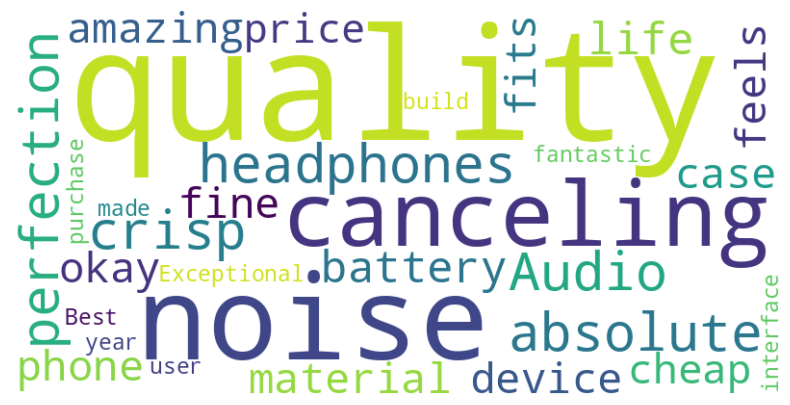

In [10]:
import ssl
import nltk
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

try:
    ssl._create_default_https_context = ssl._create_unverified_context
except AttributeError:
    pass

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

reviews = [
    "The noise-canceling headphones are absolute perfection! Audio quality is crisp and battery life is amazing.",
    "Extremely disappointed with the service. Delivery was delayed by two weeks and customer support was unhelpful.",
    "The phone case is okay. It fits the device fine, but the material feels cheap for the price.",
    "Exceptional build quality and fantastic user interface. Best purchase I have made this year!",
    "Terrible build quality. The battery overheats quickly and the screen cracked after a minor bump."
]

positive_reviews_text = ""

for i, review in enumerate(reviews, 1):
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews_text += review + " "
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review {i}: Polarity = {polarity:.2f}, Subjectivity = {subjectivity:.2f} | Category: {sentiment}")

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(positive_reviews_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

**Ques6**

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """
Artificial intelligence is driving modern technological innovation across the global economy.
Machine learning models learn patterns from data to automate complex tasks efficiently.
Deep learning networks analyze image data process natural language and generate human like speech.
Ethical development ensures that AI models remain unbiased safe and beneficial to society.
Engineers build neural networks to solve difficult problems in science medicine and engineering.
As computing power expands intelligent machines will continue to shape the future of human society.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in training_text.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i+1])

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam')
model.fit(X, y, epochs=120, verbose=0)

seed_text = "artificial intelligence"
next_words = 12

for _ in range(next_words):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
    predicted_probs = model.predict(token_list, verbose=0)
    predicted_word_idx = np.argmax(predicted_probs, axis=-1)[0]

    output_word = ""
    for word, index in tokenizer.word_index.items():
        if index == predicted_word_idx:
            output_word = word
            break
    seed_text += " " + output_word

print("Generated Output:")
print(seed_text)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Generated Output:
artificial intelligence is modern technological technological innovation across the global economy economy efficiently efficiently
